## Question 2

 ### Imports and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
#  folder for Q2 figures
os.makedirs('../outputs/figures', exist_ok=True)

# 1. Load clean dataset
df = pd.read_csv('../data/cleaned_rfe_data.csv')

# 2. Separate Features (X) and Target (y)
X = df.drop(columns=['Major_Service_Required'])
y = df['Major_Service_Required']



In [3]:
df.head()

,Impact_Damage_History,Average_Bearing_Temperature_C,Coolant_Temperature_C,Sensor_Health_Score,Mechanical_Condition_Score,Error_Log_Alert,Irregular_Vibration_Alert,Maintenance_Compliance_Score,Major_Service_Required
0,-0.318673,-1.600207,-1.126534,0.761243,0.498538,-0.510439,-0.437884,-1.107404,0.0
1,-0.318673,0.653781,0.436670,-0.876573,0.282061,-0.510439,-0.437884,0.709866,NaN
2,-0.318673,-1.386440,0.379720,-0.106282,1.347449,-0.510439,2.283709,0.494798,0.0
3,-0.318673,1.697871,0.839849,1.464094,0.148479,-0.510439,-0.437884,1.348726,0.0
4,3.138014,-1.685573,0.296378,-1.502550,0.340032,-0.510439,-0.437884,1.423066,NaN


In [4]:
df.shape

(1703, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1703 entries, 0 to 1702
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Impact_Damage_History          1703 non-null   float64
 1   Average_Bearing_Temperature_C  1703 non-null   float64
 2   Coolant_Temperature_C          1703 non-null   float64
 3   Sensor_Health_Score            1703 non-null   float64
 4   Mechanical_Condition_Score     1703 non-null   float64
 5   Error_Log_Alert                1703 non-null   float64
 6   Irregular_Vibration_Alert      1703 non-null   float64
 7   Maintenance_Compliance_Score   1703 non-null   float64
 8   Major_Service_Required         1349 non-null   float64
dtypes: float64(9)
memory usage: 119.9 KB


#### 2.1 Stratified 75/25 Split & Train Models

In [7]:
#  Drop any rows where the target variable is NaN
df = df.dropna(subset=['Major_Service_Required'])

# Separate Features (X) and Target (y) 
X = df.drop(columns=['Major_Service_Required'])
y = df['Major_Service_Required']

# stratified 75/25 training and test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Initialize the models with reproducible settings
log_reg = LogisticRegression(random_state=42)
dt_classifier = DecisionTreeClassifier(random_state=42)

# Train both models
log_reg.fit(X_train, y_train)
dt_classifier.fit(X_train, y_train)

print("Models trained successfully!")

Models trained successfully!


### 2.2 Model Performance Evaluation

In [9]:
# Make predictions on the test set using both models
y_pred_lr = log_reg.predict(X_test)
y_pred_dt = dt_classifier.predict(X_test)

# Create a function to display the metrics clearly
def evaluate_model(y_true, y_pred, model_name):
    print(f"--- {model_name} ---")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
    print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\n")

# Print the evaluation metrics for both models
evaluate_model(y_test, y_pred_lr, "Logistic Regression")
evaluate_model(y_test, y_pred_dt, "Decision Tree")



--- Logistic Regression ---
Accuracy:  0.6598
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
Confusion Matrix:
[[223   3]
 [112   0]]


--- Decision Tree ---
Accuracy:  0.5503
Precision: 0.3387
Recall:    0.3750
F1-Score:  0.3559
Confusion Matrix:
[[144  82]
 [ 70  42]]




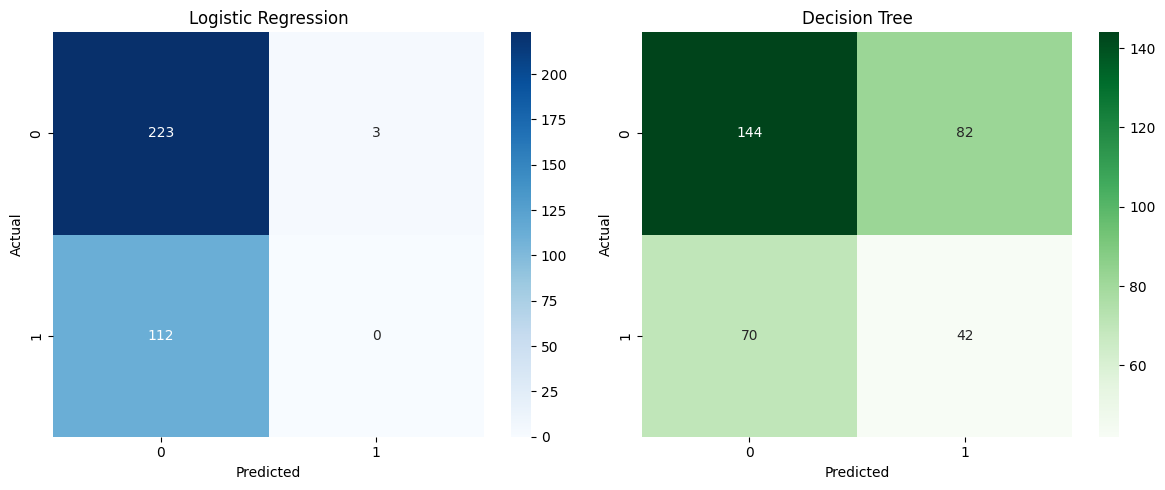

In [10]:
# Plot and save the confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Decision Tree')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('../outputs/figures/q2_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()